## Import Libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

sns.set_style("whitegrid")

from sklearn.preprocessing import StandardScaler

import statsmodels.formula.api as smf
import statsmodels.api as sm

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [7]:
df = pd.read_csv("/Users/sophieakin/Projects/DATA5100/education/data/education_clean.csv")

In [8]:
df.head(5)

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [9]:
df_census = pd.read_csv("/Users/sophieakin/Projects/DATA5100/education/data/education_census.csv")

In [76]:
df_census.head(5)

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,percent_snap,percent_health_insurance
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,11.2%,5.7%
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,11.2%,5.7%
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,11.2%,5.7%
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,11.2%,5.7%
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,11.2%,5.7%


In [78]:
df_census = df_census.rename({'\xa0\xa0\xa0\xa0With Food Stamp/SNAP benefits in the past 12 months': 'percent_snap', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0No health insurance coverage':'percent_health_insurance'})

In [84]:
df_census['percent_snap'] = df_census['percent_snap'].str[:-1].astype(float)

In [85]:
df_census['percent_health_insurance'] = df_census['percent_health_insurance'].str[:-1].astype(float)

## Exploratory Data Analysis

### Exploring the relationships between the variables

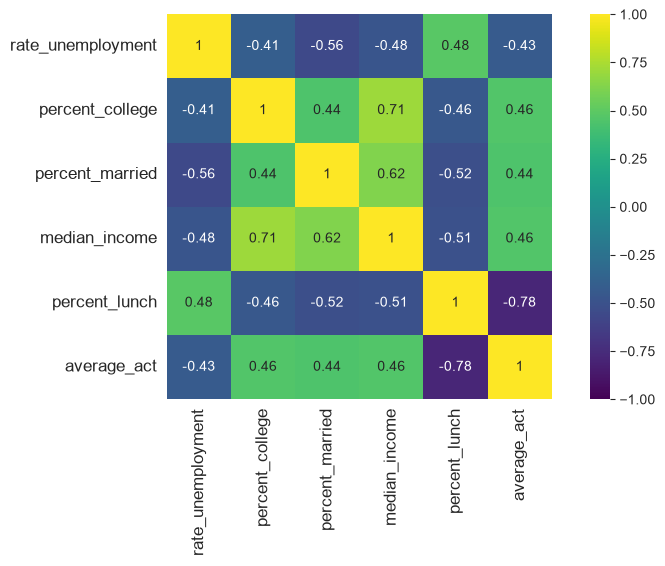

In [11]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

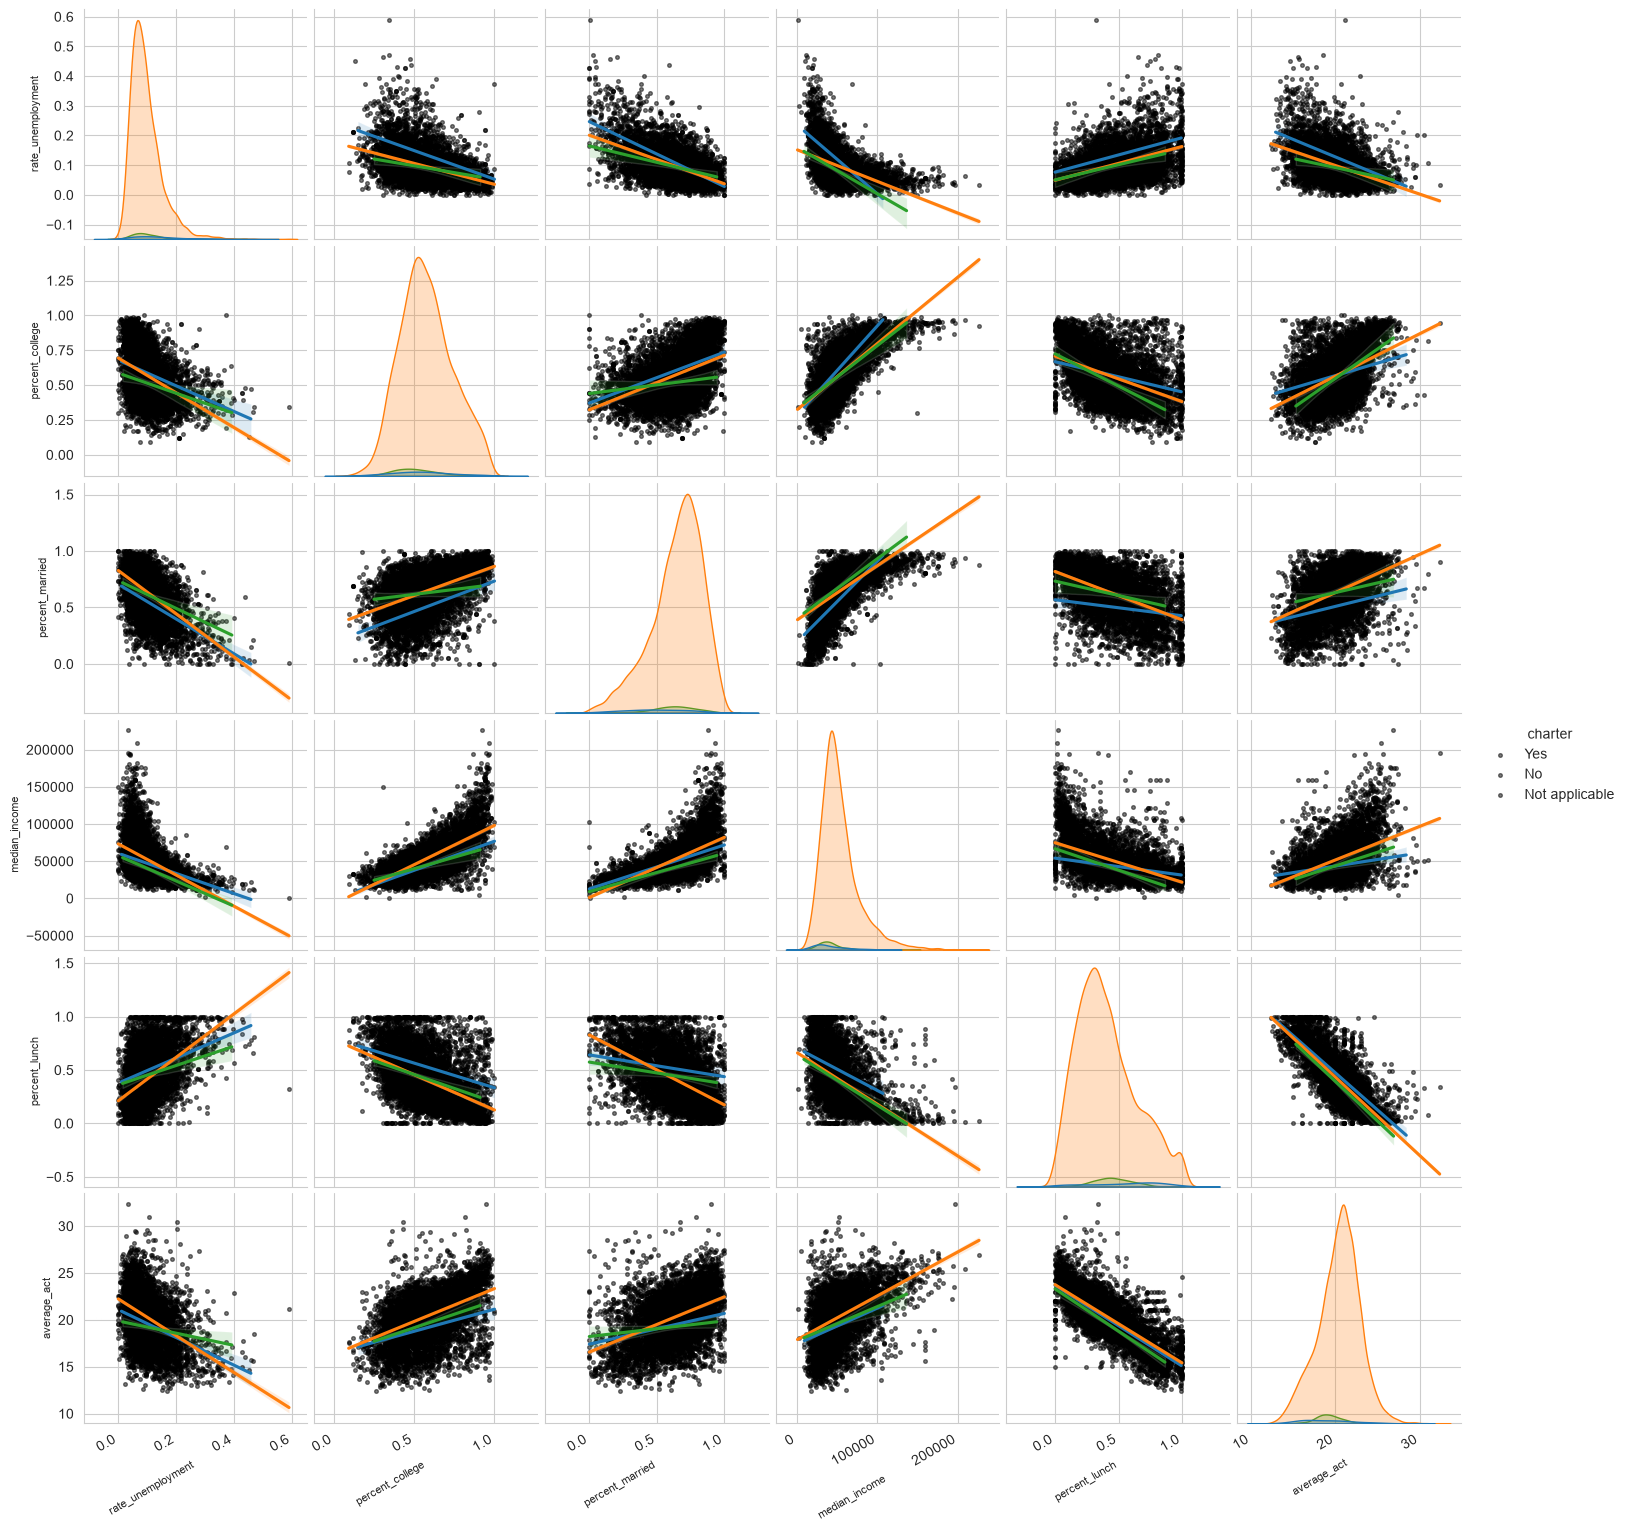

In [12]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

It appears that percent lunch has the highest correlation coefficient with act scores.

### Identifying Outliers

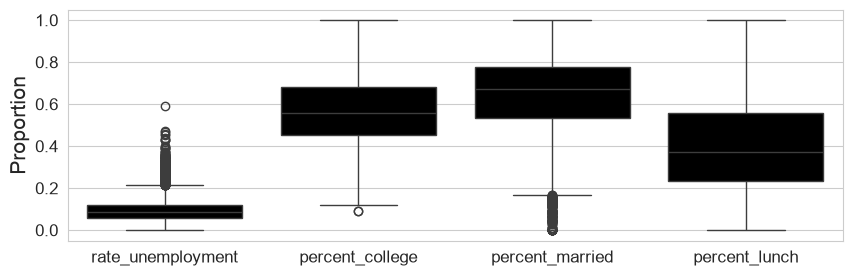

In [13]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

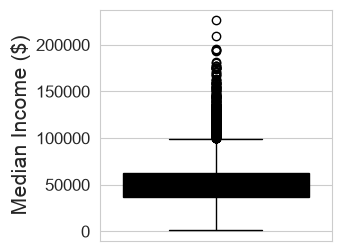

In [14]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

#### Median income appears to have strong outliers. Will add a column that shows the ratio from the regional median income

In [15]:
regional_median = df.groupby('state')['median_income'].transform('median')

In [16]:
regional_median

0       57214.5
1       57214.5
2       57214.5
3       57214.5
4       57214.5
         ...   
7222    53897.0
7223    53897.0
7224    53897.0
7225    53897.0
7226    53897.0
Name: median_income, Length: 7227, dtype: float64

In [17]:
df['local_income_ratio'] = df['median_income'] / regional_median

In [18]:
df.head(3)

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,local_income_ratio
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,0.748412
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,1.561143
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,1.470606


In [19]:
df['charter'].unique()

<ArrowStringArray>
['Yes', 'No', 'Not applicable']
Length: 3, dtype: str

##### Calculated the regional median income by grouping by state and finding the median. Added a variable, local_income_ratio which compares the school's median income to the regional median income

## Modeling

### Median Income Assesment

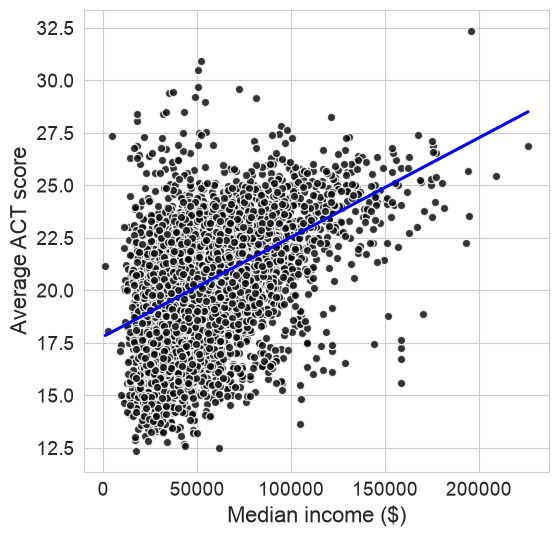

In [20]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)

plt.show()

#### Fit the simple linear regression model

In [21]:
model_median_income = smf.ols(formula = 'average_act ~ median_income', data = df).fit()

In [22]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:23:57   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

The R-squared value is 0.211 which shows a relatively weak correlation; however, the p-value is small which supports the relationship between the two.

##### Compute the RSME and MAE

In [23]:
y_hat = model_median_income.predict()

In [24]:
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

np.float64(2.228)

In [33]:
mean_absolute_error(df['average_act'], y_hat)

1.712938698068855

##### The RSME and MAE values is small, which supports the claim that the linear cmodel matches the actual values.

#### Fit a quadratic linear regression model

In [88]:
model_median_income2 = smf.ols(
    formula = 'average_act ~ median_income + I(median_income**2)',
    data = df).fit()

In [27]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:24:18   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

##### The quadratic linear regression model shows a slightly higher R-squared value, 0.219 vs 0.211. Which suggests a slight better fit, compared to the standard linear regression model. The p-value is also very small. 

##### Compare model fit and accuracy

In [ ]:
model_median_income2.pvalues

In [ ]:
anova_lm(model_median_income, model_median_income2)

##### The p-value suggests there is a statistical significance between the two models.

##### Calculate mean absolute error

In [34]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.6972389257635734

In [36]:
np.sqrt(mean_absolute_error(df['average_act'], y_hat)).round(3) 

np.float64(1.309)

##### The Mean absolute error is 1.697 and the RMSE is 1.309. These are relatively small, and support the claim that the model is a good fit.

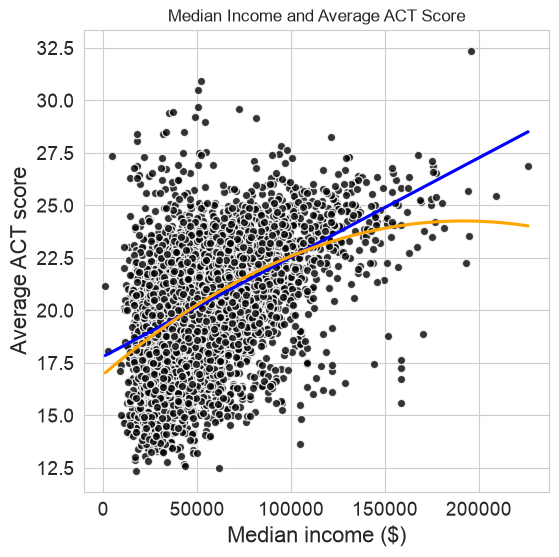

In [140]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           order = 2, 
           color = 'orange',
           ci = False,
           scatter = False)

plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)
plt.title('')
plt.tick_params(labelsize = 14)
plt.title('Median Income and Average ACT Score')
plt.savefig("linear_quadratic_plot.png")
plt.show()

##### This scatterplot shows the difference between the two models. The linear model is blue and the quadratic model is orange

### Median Income Ratio Change Assessment

#### Determine if the percent change from regional median income results in a stronger correlation with ACT scores. Take the log of local income ratio to highlight disparities.

In [37]:
df['log_local_income_ratio'] = np.log1p(df['local_income_ratio'])

In [38]:
model_log_ratio = smf.ols(
    formula = 'average_act ~ log_local_income_ratio + I(log_local_income_ratio**2)',
    data = df).fit()

In [39]:
print(model_log_ratio.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.180
Model:                            OLS   Adj. R-squared:                  0.180
Method:                 Least Squares   F-statistic:                     792.4
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          7.37e-312
Time:                        18:35:54   Log-Likelihood:                -16184.
No. Observations:                7227   AIC:                         3.237e+04
Df Residuals:                    7224   BIC:                         3.239e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

In [40]:
anova_lm(model_median_income, model_log_ratio)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012794,0.0,NaN,NaN,NaN
1,7224.0,37287.058858,1.0,-1422.046064,-275.507403,1.0


##### The log ratio of the school's median income to log regional median income does not return a stronger r-squared value. Additionally the p-value is large which supports the claim that there is no meaningful difference between the two.

### Multiple linear regression

In [102]:
model = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + percent_snap + percent_health_insurance ',
    data = df_census).fit()

In [103]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.629
Method:                 Least Squares   F-statistic:                     1748.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:23:18   Log-Likelihood:                -13318.
No. Observations:                7227   AIC:                         2.665e+04
Df Residuals:                    7219   BIC:                         2.671e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [104]:
mean_absolute_error(df['average_act'], model.predict())

1.1444029247914933

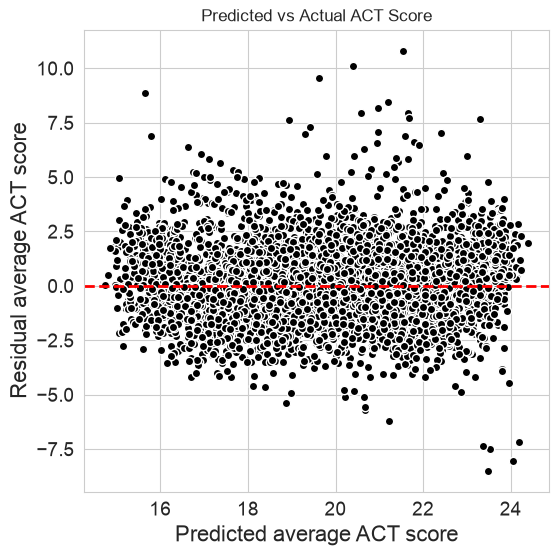

In [141]:
y_hat = model.predict()
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

plt.tick_params(labelsize = 14)
plt.title('Predicted vs Actual ACT Score')
plt.savefig("multiple_linear_plot.png")
plt.show()

####  The multiple linear regresion model with all socioeconomic predictors has an r-squared value of 0.628 which suggests a much stronger correlation than one indicator alone. Percent lunch appears to have the highest correlation coefficient, followed by unemployment rate and percent college.

#### Determine if there is a difference if the model only uses the top 3 indicators

In [105]:
model_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data = df_census).fit()

In [106]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:30:16   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

In [107]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.1454832950346379

In [108]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
             'R-squared': [r2_full, r2_reduced]},
            index = ['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1444,0.6289
reduced model,1.1455,0.6279


In [109]:
anova_lm(model_reduced, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7219.0,16870.754587,4.0,45.864581,4.906366,0.000598


#### The reduced model resulted in a small change on the model. 

### Scale the predictor values to determine their effect

In [125]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch', 'percent_snap', 'percent_health_insurance']
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_married_normalized', 'median_income_normalized', 'percent_lunch_normalized', 'percent_snap_normalized', 'percent_health_insurance_normalized']


In [126]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(df_census[predictor_variables])

In [128]:
df_census[scaled_columns] = scaler.transform(df_census[predictor_variables])

#### Check mean and standard deviation

In [129]:
df_census[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_married_normalized,median_income_normalized,percent_lunch_normalized,percent_snap_normalized,percent_health_insurance_normalized
mean,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### confirmed caluculations were performed properly

In [132]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + percent_snap + percent_health_insurance',
    data = df_census).fit()

#### Compare Accuracy

In [133]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.629
Method:                 Least Squares   F-statistic:                     1748.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:03:13   Log-Likelihood:                -13318.
No. Observations:                7227   AIC:                         2.665e+04
Df Residuals:                    7219   BIC:                         2.671e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [134]:
mae_normalized = mean_absolute_error(df_census['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df_census['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
             'R-squared': [r2_normalized, r2_reduced]},
            index = ['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1444,0.6289
reduced model,1.1455,0.6279


#### The transfomations do not result in an overall change in the model, however, it allows for the comparison of each indicator's effect. Percent Lunch remains the strongest indicator of ACT Score